
# Post-hoc tuning the cut-off point of decision function

Once a binary classifier is trained, the :term:`predict` method outputs class label
predictions corresponding to a thresholding of either the :term:`decision_function` or
the :term:`predict_proba` output. The default threshold is defined as a posterior
probability estimate of 0.5 or a decision score of 0.0. However, this default strategy
may not be optimal for the task at hand.

This example shows how to use the
:class:`~sklearn.model_selection.TunedThresholdClassifierCV` to tune the decision
threshold, depending on a metric of interest.


In [1]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

## The diabetes dataset

To illustrate the tuning of the decision threshold, we will use the diabetes dataset.
This dataset is available on OpenML: https://www.openml.org/d/37. We use the
:func:`~sklearn.datasets.fetch_openml` function to fetch this dataset.



In [2]:
from sklearn.datasets import fetch_openml

diabetes = fetch_openml(data_id=37, as_frame=True, parser="pandas")
data, target = diabetes.data, diabetes.target

We look at the target to understand the type of problem we are dealing with.



In [3]:
target.value_counts()

class
tested_negative    500
tested_positive    268
Name: count, dtype: int64

We can see that we are dealing with a binary classification problem. Since the
labels are not encoded as 0 and 1, we make it explicit that we consider the class
labeled "tested_negative" as the negative class (which is also the most frequent)
and the class labeled "tested_positive" the positive as the positive class:



In [4]:
neg_label, pos_label = target.value_counts().index

We can also observe that this binary problem is slightly imbalanced where we have
around twice more samples from the negative class than from the positive class. When
it comes to evaluation, we should consider this aspect to interpret the results.

## Our vanilla classifier

We define a basic predictive model composed of a scaler followed by a logistic
regression classifier.



In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), LogisticRegression())
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio 

We evaluate our model using cross-validation. We use the accuracy and the balanced
accuracy to report the performance of our model. The balanced accuracy is a metric
that is less sensitive to class imbalance and will allow us to put the accuracy
score in perspective.

Cross-validation allows us to study the variance of the decision threshold across
different splits of the data. However, the dataset is rather small and it would be
detrimental to use more than 5 folds to evaluate the dispersion. Therefore, we use
a :class:`~sklearn.model_selection.RepeatedStratifiedKFold` where we apply several
repetitions of 5-fold cross-validation.



In [6]:
import pandas as pd

from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

scoring = ["accuracy", "balanced_accuracy"]
cv_scores = [
    "train_accuracy",
    "test_accuracy",
    "train_balanced_accuracy",
    "test_balanced_accuracy",
]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
cv_results_vanilla_model = pd.DataFrame(
    cross_validate(
        model,
        data,
        target,
        scoring=scoring,
        cv=cv,
        return_train_score=True,
        return_estimator=True,
    )
)
cv_results_vanilla_model[cv_scores].aggregate(["mean", "std"]).T

,mean,std
train_accuracy,0.779751,0.007822
test_accuracy,0.770926,0.030585
train_balanced_accuracy,0.732913,0.009788
test_balanced_accuracy,0.723665,0.035914


Our predictive model succeeds to grasp the relationship between the data and the
target. The training and testing scores are close to each other, meaning that our
predictive model is not overfitting. We can also observe that the balanced accuracy is
lower than the accuracy, due to the class imbalance previously mentioned.

For this classifier, we let the decision threshold, used convert the probability of
the positive class into a class prediction, to its default value: 0.5. However, this
threshold might not be optimal. If our interest is to maximize the balanced accuracy,
we should select another threshold that would maximize this metric.

The :class:`~sklearn.model_selection.TunedThresholdClassifierCV` meta-estimator allows
to tune the decision threshold of a classifier given a metric of interest.

## Tuning the decision threshold

We create a :class:`~sklearn.model_selection.TunedThresholdClassifierCV` and
configure it to maximize the balanced accuracy. We evaluate the model using the same
cross-validation strategy as previously.



In [7]:
from sklearn.model_selection import TunedThresholdClassifierCV

tuned_model = TunedThresholdClassifierCV(estimator=model, scoring="balanced_accuracy")
cv_results_tuned_model = pd.DataFrame(
    cross_validate(
        tuned_model,
        data,
        target,
        scoring=scoring,
        cv=cv,
        return_train_score=True,
        return_estimator=True,
    )
)
cv_results_tuned_model[cv_scores].aggregate(["mean", "std"]).T

,mean,std
train_accuracy,0.752470,0.015579
test_accuracy,0.739950,0.036592
train_balanced_accuracy,0.757915,0.009747
test_balanced_accuracy,0.744029,0.035445


In comparison with the vanilla model, we observe that the balanced accuracy score
increased. Of course, it comes at the cost of a lower accuracy score. It means that
our model is now more sensitive to the positive class but makes more mistakes on the
negative class.

However, it is important to note that this tuned predictive model is internally the
same model as the vanilla model: they have the same fitted coefficients.



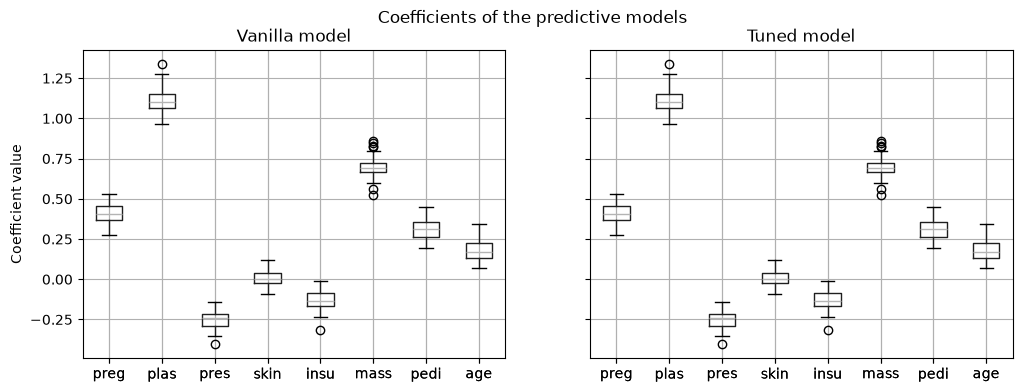

In [8]:
import matplotlib.pyplot as plt

vanilla_model_coef = pd.DataFrame(
    [est[-1].coef_.ravel() for est in cv_results_vanilla_model["estimator"]],
    columns=diabetes.feature_names,
)
tuned_model_coef = pd.DataFrame(
    [est.estimator_[-1].coef_.ravel() for est in cv_results_tuned_model["estimator"]],
    columns=diabetes.feature_names,
)

fig, ax = plt.subplots(ncols=2, figsize=(12, 4), sharex=True, sharey=True)
vanilla_model_coef.boxplot(ax=ax[0])
ax[0].set_ylabel("Coefficient value")
ax[0].set_title("Vanilla model")
tuned_model_coef.boxplot(ax=ax[1])
ax[1].set_title("Tuned model")
_ = fig.suptitle("Coefficients of the predictive models")

Only the decision threshold of each model was changed during the cross-validation.



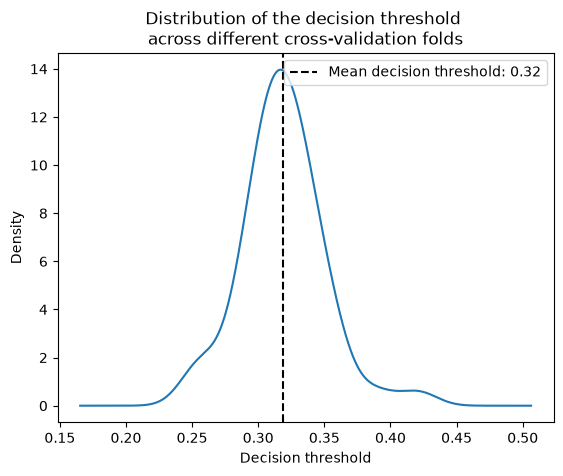

In [9]:
decision_threshold = pd.Series(
    [est.best_threshold_ for est in cv_results_tuned_model["estimator"]],
)
ax = decision_threshold.plot.kde()
ax.axvline(
    decision_threshold.mean(),
    color="k",
    linestyle="--",
    label=f"Mean decision threshold: {decision_threshold.mean():.2f}",
)
ax.set_xlabel("Decision threshold")
ax.legend(loc="upper right")
_ = ax.set_title(
    "Distribution of the decision threshold \nacross different cross-validation folds"
)

In average, a decision threshold around 0.32 maximizes the balanced accuracy, which is
different from the default decision threshold of 0.5. Thus tuning the decision
threshold is particularly important when the output of the predictive model
is used to make decisions. Besides, the metric used to tune the decision threshold
should be chosen carefully. Here, we used the balanced accuracy but it might not be
the most appropriate metric for the problem at hand. The choice of the "right" metric
is usually problem-dependent and might require some domain knowledge. Refer to the
example entitled,
`sphx_glr_auto_examples_model_selection_plot_cost_sensitive_learning.py`,
for more details.

